### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.

### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [1]:
# Libraries used throughout the analysis
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style='whitegrid')

In [2]:
def acceptance_rate(df, mask):
    """Return acceptance rate and count for rows matching `mask` vs. everyone else."""
    return pd.DataFrame({
        'group': ['Matches condition', 'All others'],
        'drivers': [mask.sum(), (~mask).sum()],
        'acceptance_rate': [df.loc[mask, 'Y'].mean(), df.loc[~mask, 'Y'].mean()]
    }).round(3)


def plot_rate(df, column, ax, order=None, title=None):
    """Bar chart of acceptance rate for each value of `column`."""
    rates = df.groupby(column)['Y'].mean().mul(100)
    if order is not None:
        rates = rates.reindex(order)
    sns.barplot(x=rates.index, y=rates.values, ax=ax, color='steelblue')
    ax.axhline(df['Y'].mean() * 100, color='red', linestyle='--', label='Average for these coupons')
    ax.set_title(title or f'Acceptance rate by {column}')
    ax.set_xlabel('')
    ax.set_ylabel('Accepted (%)')
    ax.set_ylim(0, 100)
    ax.legend(loc='upper right')
    ax.tick_params(axis='x', rotation=30)

Two small helpers are defined above so the same comparison and plot style can be reused for every question: `acceptance_rate` compares a group against everyone else, and `plot_rate` shows the acceptance rate for each value of a feature against the overall rate (red line).

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.

In [3]:
data = pd.read_csv('data/coupons.csv')

In [4]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [5]:
print(f'Rows: {data.shape[0]:,}  Columns: {data.shape[1]}')
print(f'Duplicate rows: {data.duplicated().sum()}')

# Missing values per column (only columns with gaps)
missing = data.isnull().sum()
missing[missing > 0].to_frame('missing').assign(pct=lambda d: (d['missing'] / len(data) * 100).round(1))

Rows: 12,684  Columns: 26
Duplicate rows: 74


,missing,pct
car,12576,99.1
Bar,107,0.8
CoffeeHouse,217,1.7
CarryAway,151,1.2
RestaurantLessThan20,130,1.0
Restaurant20To50,189,1.5


In [6]:
# Columns with a single value carry no information
data.nunique().sort_values().head(4)

toCoupon_GEQ5min    1
expiration          2
has_children        2
gender              2
dtype: int64

**What the checks show**
- `car` is missing in 12,576 of 12,684 rows (99%) — it can't be used.
- The five visit-frequency columns (`Bar`, `CoffeeHouse`, `CarryAway`, `RestaurantLessThan20`, `Restaurant20To50`) each have 1–2% missing values.
- There are 74 exact duplicate rows.
- `toCoupon_GEQ5min` is always 1, so it adds nothing.
- The column `passanger` is misspelled.

3. Decide what to do about your missing data -- drop, replace, other...

In [7]:
coupons = (data
           .drop(columns=['car', 'toCoupon_GEQ5min'])   # almost all missing / constant
           .drop_duplicates()                            # remove 74 repeated survey rows
           .rename(columns={'passanger': 'passenger'}))  # fix the typo

# Frequency columns are only ~1-2% missing, so dropping those rows loses very little data
frequency_cols = ['Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50']
coupons = coupons.dropna(subset=frequency_cols)

print(f'Rows after cleaning: {len(coupons):,} ({len(coupons) / len(data):.1%} of the original)')
print(f'Missing values left: {coupons.isnull().sum().sum()}')

Rows after cleaning: 12,007 (94.7% of the original)
Missing values left: 0


**Decision:** drop `car` (99% missing) and `toCoupon_GEQ5min` (constant), remove duplicates, and drop the ~5% of rows with a missing visit frequency. Filling those values (e.g. with "never") would invent behaviour we don't know, and losing ~5% of rows doesn't change the overall acceptance rate.

4. What proportion of the total observations chose to accept the coupon?

In [8]:
overall_rate = coupons['Y'].mean()
print(f'Overall acceptance rate: {overall_rate:.1%}')
coupons['Y'].value_counts().rename({1: 'Accepted', 0: 'Rejected'})

Overall acceptance rate: 56.8%


Y
Accepted    6825
Rejected    5182
Name: count, dtype: int64

About **57%** of all coupons were accepted, so slightly more drivers say yes than no.

5. Use a bar plot to visualize the `coupon` column.

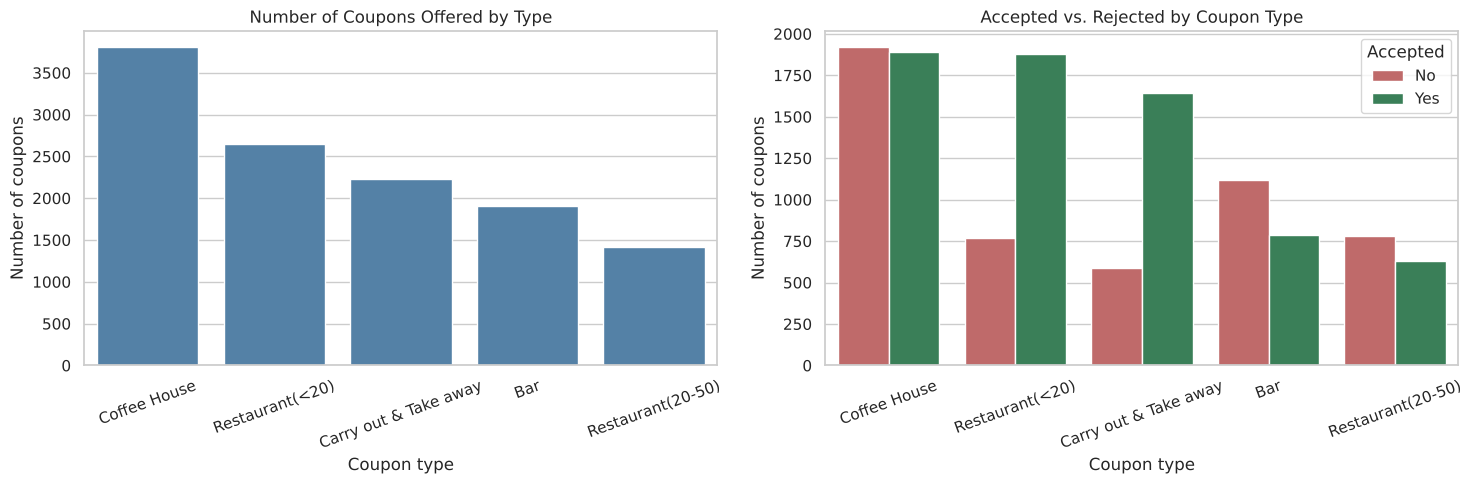

coupon
Carry out & Take away    73.6
Restaurant(<20)          71.0
Coffee House             49.6
Restaurant(20-50)        44.7
Bar                      41.2
Name: acceptance_%, dtype: float64

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# How many coupons of each type were offered
order = coupons['coupon'].value_counts().index
sns.countplot(data=coupons, x='coupon', order=order, color='steelblue', ax=axes[0])
axes[0].set_title('Number of Coupons Offered by Type')
axes[0].set_xlabel('Coupon type')
axes[0].set_ylabel('Number of coupons')
axes[0].tick_params(axis='x', rotation=20)

# Accepted vs rejected within each coupon type
sns.countplot(data=coupons, x='coupon', hue='Y', order=order, palette=['indianred', 'seagreen'], ax=axes[1])
axes[1].set_title('Accepted vs. Rejected by Coupon Type')
axes[1].set_xlabel('Coupon type')
axes[1].set_ylabel('Number of coupons')
axes[1].legend(title='Accepted', labels=['No', 'Yes'])
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('images/coupon_types.png', dpi=100)
plt.show()

coupons.groupby('coupon')['Y'].mean().sort_values(ascending=False).mul(100).round(1).rename('acceptance_%')

Coffee house coupons are offered most often. Carry-out and cheap restaurant (<\$20) coupons are accepted most (over 70%), while **bar coupons are accepted least (about 41%)**, followed by expensive restaurants (\$20–50).

6. Use a histogram to visualize the temperature column.

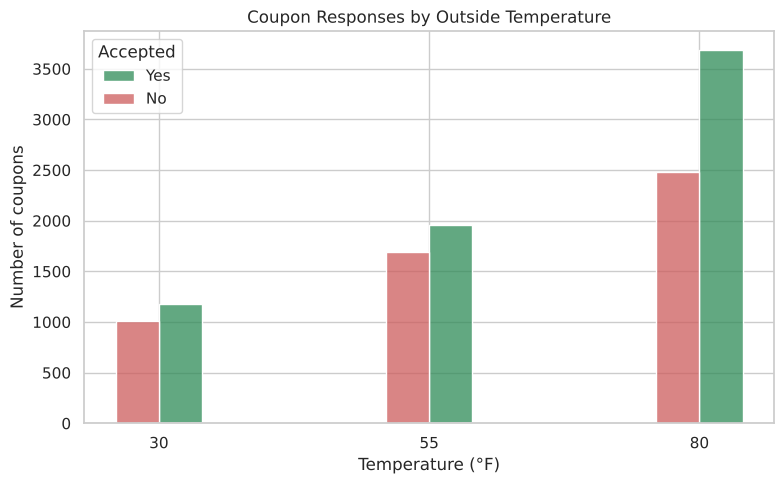

temperature
30    53.8
55    53.7
80    59.8
Name: acceptance_%, dtype: float64

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=coupons, x='temperature', hue='Y', multiple='dodge', discrete=True,
             shrink=8, palette=['indianred', 'seagreen'], ax=ax)
ax.set_title('Coupon Responses by Outside Temperature')
ax.set_xlabel('Temperature (°F)')
ax.set_ylabel('Number of coupons')
ax.set_xticks([30, 55, 80])
ax.legend(title='Accepted', labels=['Yes', 'No'])
plt.tight_layout()
plt.savefig('images/temperature.png', dpi=100)
plt.show()

coupons.groupby('temperature')['Y'].mean().mul(100).round(1).rename('acceptance_%')

The survey only uses three temperatures (30, 55 and 80°F). Most scenarios are at 80°F, and acceptance is highest there (~60%) compared with ~53% at the two colder temperatures.

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.

In [11]:
bar_coupons = coupons[coupons['coupon'] == 'Bar'].copy()
print(f'Bar coupons: {len(bar_coupons):,}')
bar_coupons.head()

Bar coupons: 1,906


,destination,passenger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,never,less1,4~8,4~8,less1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,never,less1,4~8,4~8,less1,0,0,1,0,1
39,Work,Alone,Sunny,55,7AM,Bar,1d,Male,21,Single,...,never,less1,4~8,4~8,less1,1,1,0,1,1
46,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,46,Single,...,never,4~8,1~3,1~3,never,0,0,0,1,0
57,Home,Alone,Sunny,55,6PM,Bar,1d,Male,46,Single,...,never,4~8,1~3,1~3,never,0,0,1,0,0


2. What proportion of bar coupons were accepted?

In [12]:
bar_rate = bar_coupons['Y'].mean()
print(f'Bar coupon acceptance rate: {bar_rate:.1%}')

Bar coupon acceptance rate: 41.2%


Only about **41%** of bar coupons were accepted — well below the 57% overall rate.

3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.

In [13]:
# 'never', 'less1', '1~3' = 3 or fewer visits a month; '4~8', 'gt8' = more than 3
three_or_fewer = bar_coupons['Bar'].isin(['never', 'less1', '1~3'])
acceptance_rate(bar_coupons, three_or_fewer).replace(
    {'Matches condition': '3 or fewer bar visits/month', 'All others': 'More than 3 visits/month'})

,group,drivers,acceptance_rate
0,3 or fewer bar visits/month,1713,0.372
1,More than 3 visits/month,193,0.762


Drivers who go to a bar **more than 3 times a month accept about 76%** of bar coupons, about double the rate of those who go 3 or fewer times (37%).

4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?

In [14]:
more_than_once = bar_coupons['Bar'].isin(['1~3', '4~8', 'gt8'])
over_25 = ~bar_coupons['age'].isin(['below21', '21'])   # age codes: below21, 21 (21-25), 26, 31, ...
acceptance_rate(bar_coupons, more_than_once & over_25)

,group,drivers,acceptance_rate
0,Matches condition,403,0.690
1,All others,1503,0.337


Yes — there is a big difference. Drivers who visit bars more than once a month **and** are over 25 accept about **69%** of bar coupons, compared with about 34% for everyone else.

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.

In [15]:
no_kids = bar_coupons['passenger'] != 'Kid(s)'
not_farming = bar_coupons['occupation'] != 'Farming Fishing & Forestry'
acceptance_rate(bar_coupons, more_than_once & no_kids & not_farming)

,group,drivers,acceptance_rate
0,Matches condition,530,0.709
1,All others,1376,0.297


Again a large gap: about **71%** acceptance for frequent bar-goers without kids in the car (and not in farming/fishing/forestry) vs. about 30% for all others. The occupation filter removes very few people, so most of the effect comes from bar frequency and having no kids in the car.

6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.

In [16]:
under_30 = bar_coupons['age'].isin(['below21', '21', '26'])
not_widowed = bar_coupons['maritalStatus'] != 'Widowed'
cheap_restaurant_4plus = bar_coupons['RestaurantLessThan20'].isin(['4~8', 'gt8'])
income_under_50k = bar_coupons['income'].isin(['Less than $12500', '$12500 - $24999',
                                               '$25000 - $37499', '$37500 - $49999'])

groups = {
    'Bar >1/month, no kid passengers, not widowed': more_than_once & no_kids & not_widowed,
    'Bar >1/month, under 30': more_than_once & under_30,
    'Cheap restaurants >4/month, income <50K': cheap_restaurant_4plus & income_under_50k,
}
groups['Any of the three'] = groups[list(groups)[0]] | groups[list(groups)[1]] | groups[list(groups)[2]]

summary = pd.DataFrame({
    'drivers': {k: v.sum() for k, v in groups.items()},
    'acceptance_in_group': {k: bar_coupons.loc[v, 'Y'].mean() for k, v in groups.items()},
    'acceptance_others': {k: bar_coupons.loc[~v, 'Y'].mean() for k, v in groups.items()},
}).round(3)
summary

,drivers,acceptance_in_group,acceptance_others
"Bar >1/month, no kid passengers, not widowed",530,0.709,0.297
"Bar >1/month, under 30",328,0.720,0.348
"Cheap restaurants >4/month, income <50K",333,0.456,0.402
Any of the three,746,0.587,0.299


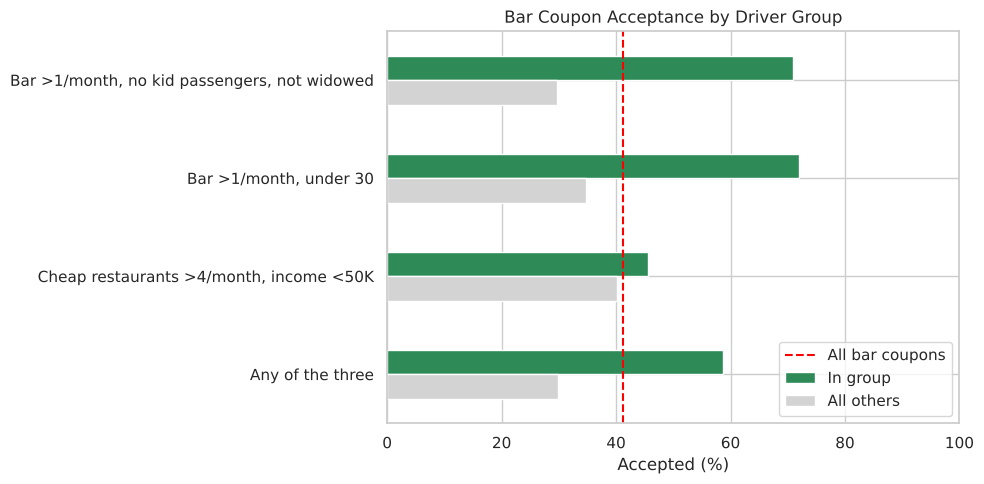

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_df = summary[['acceptance_in_group', 'acceptance_others']].mul(100)
plot_df.columns = ['In group', 'All others']
plot_df.plot(kind='barh', ax=ax, color=['seagreen', 'lightgray'])
ax.axvline(bar_rate * 100, color='red', linestyle='--', label='All bar coupons')
ax.set_title('Bar Coupon Acceptance by Driver Group')
ax.set_xlabel('Accepted (%)')
ax.set_ylabel('')
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('images/bar_groups.png', dpi=100)
plt.show()

- The two bar-frequency groups both accept around **71–72%**.
- The cheap-restaurant/low-income group is barely above average (~46% vs. 40%), so income and restaurant habits on their own say little about bar coupons.
- Together, drivers who match any of the three conditions accept about 59% vs. 30% for the rest.

7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

**Hypothesis:** whether a driver accepts a bar coupon depends mostly on whether they **already go to bars regularly** (more than once a month). Among those regular bar-goers, acceptance is even higher when they are **young adults (under 30)** and **don't have kids in the car**. Income, occupation and marital status make little difference once bar habits are known. In short, bar coupons work for people who already like bars; they don't convert people who rarely go.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

#### Coffee House Coupons

Coffee house coupons are the most common type in the survey (about a third of all coupons) and are accepted about half the time, so small improvements in targeting would matter most here. The question is: **which drivers, and in which situations, accept a coffee house coupon?**

In [18]:
coffee = coupons[coupons['coupon'] == 'Coffee House'].copy()
coffee_rate = coffee['Y'].mean()
print(f'Coffee house coupons: {len(coffee):,}   acceptance rate: {coffee_rate:.1%}')

Coffee house coupons: 3,809   acceptance rate: 49.6%


**Driver habits and trip context**

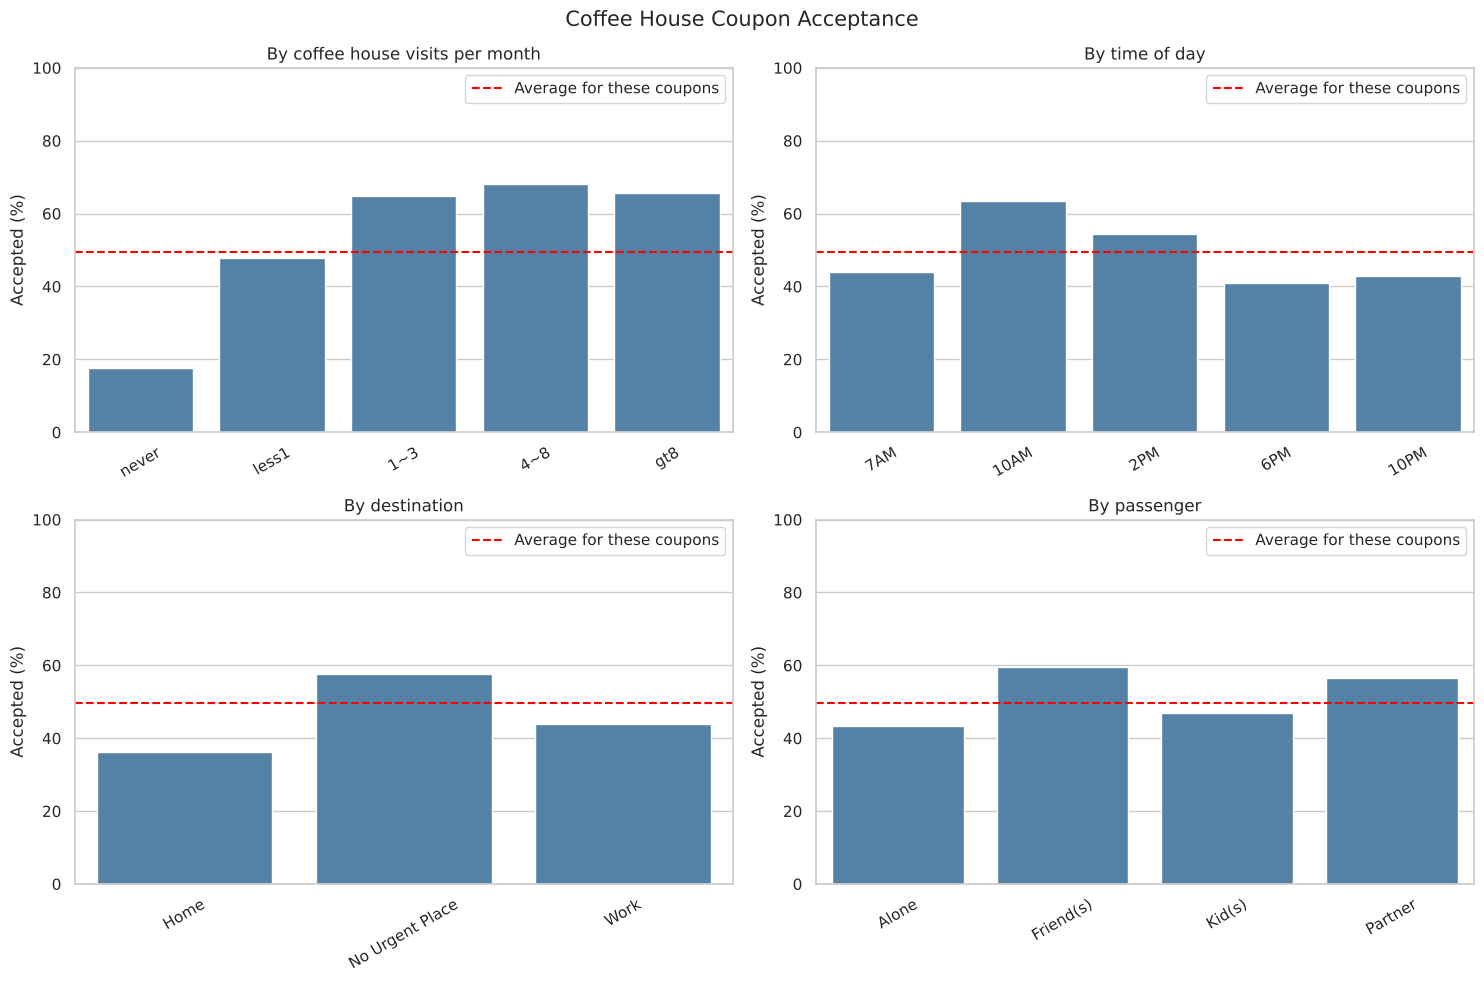

In [19]:
freq_order = ['never', 'less1', '1~3', '4~8', 'gt8']
time_order = ['7AM', '10AM', '2PM', '6PM', '10PM']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
plot_rate(coffee, 'CoffeeHouse', axes[0, 0], order=freq_order, title='By coffee house visits per month')
plot_rate(coffee, 'time', axes[0, 1], order=time_order, title='By time of day')
plot_rate(coffee, 'destination', axes[1, 0], title='By destination')
plot_rate(coffee, 'passenger', axes[1, 1], title='By passenger')
fig.suptitle('Coffee House Coupon Acceptance', fontsize=15)
plt.tight_layout()
plt.savefig('images/coffee_habits_context.png', dpi=100)
plt.show()

- **Visit frequency is the strongest signal.** People who never go to coffee houses accept only ~18% of these coupons; anyone who goes at least once a month accepts 65–68%.
- **Mid-morning and early afternoon work best**: 10AM (63%) and 2PM (55%) beat 7AM, 6PM and 10PM (41–44%).
- Drivers with **no urgent destination** accept more (58%) than those heading home (36%) or to work (44%).
- Drivers with **friends or a partner** in the car accept more (57–60%) than solo drivers (43%).

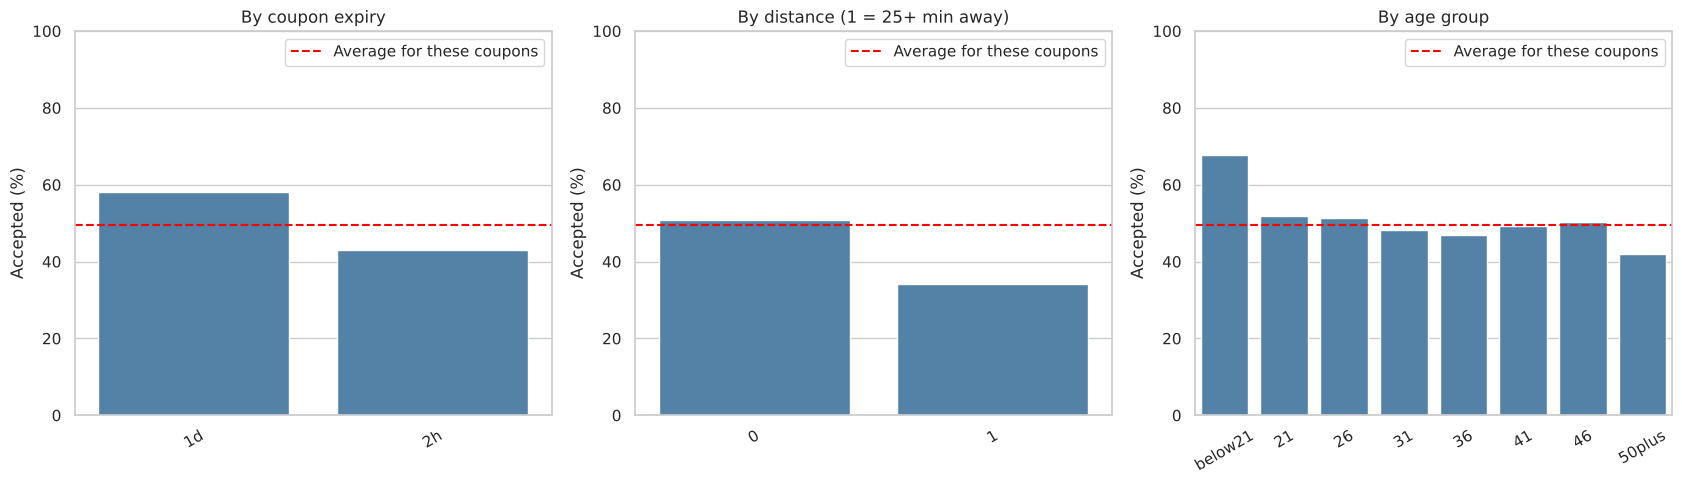

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
plot_rate(coffee, 'expiration', axes[0], title='By coupon expiry')
plot_rate(coffee, 'toCoupon_GEQ25min', axes[1], title='By distance (1 = 25+ min away)')
age_order = ['below21', '21', '26', '31', '36', '41', '46', '50plus']
plot_rate(coffee, 'age', axes[2], order=age_order, title='By age group')
plt.tight_layout()
plt.savefig('images/coffee_expiry_distance_age.png', dpi=100)
plt.show()

- Coupons valid for **1 day** are accepted more (58%) than those that expire in **2 hours** (43%).
- When the coffee house is **25+ minutes away**, acceptance drops to 34%.
- Age matters less: under-21s accept the most (68%, small group), and 50+ the least (42%); the groups in between are all close to 50%.

**Combining the strongest factors**

In [21]:
regular_visitor = coffee['CoffeeHouse'].isin(['1~3', '4~8', 'gt8'])
good_time = coffee['time'].isin(['10AM', '2PM'])
not_urgent = coffee['destination'] == 'No Urgent Place'
with_company = coffee['passenger'] != 'Alone'

combos = {
    'Regular visitor (1+ per month)': regular_visitor,
    'Regular visitor + 10AM/2PM': regular_visitor & good_time,
    'Regular visitor + no urgent place + with company': regular_visitor & not_urgent & with_company,
    'Never goes to coffee houses': coffee['CoffeeHouse'] == 'never',
}
pd.DataFrame({
    'drivers': {k: v.sum() for k, v in combos.items()},
    'acceptance_rate': {k: coffee.loc[v, 'Y'].mean() for k, v in combos.items()},
}).round(3)

,drivers,acceptance_rate
Regular visitor (1+ per month),1864,0.659
Regular visitor + 10AM/2PM,784,0.772
Regular visitor + no urgent place + with company,787,0.752
Never goes to coffee houses,896,0.175


Regular coffee drinkers who get the coupon at **10AM or 2PM accept about 77%** of the time, and regular visitors on a non-urgent trip with company accept about 75% — compared with ~50% for coffee coupons overall and only ~18% for people who never visit coffee houses.

## Findings

**Overall**
- About 57% of coupons are accepted. Cheap food coupons (carry-out, restaurants under \$20) do best (over 70%); bar coupons do worst (41%).

**Bar coupons**
- **Existing bar habits decide acceptance.** Drivers who go to bars more than 3 times a month accept about 76% of bar coupons vs. 37% for others.
- Frequent bar-goers who are **under 30** or **have no kids in the car** accept 71–72% of the time.
- Income, occupation and dining habits add little.

**Coffee house coupons**
- **Existing coffee habits decide acceptance.** People who never visit coffee houses accept only 18%; regular visitors accept 65–68%.
- **Timing and trip context matter:** acceptance is highest at 10AM and 2PM, on trips with no urgent destination, and with friends or a partner in the car.
- **Coupon design matters:** 1-day coupons beat 2-hour ones (58% vs. 43%), and coupons for places 25+ minutes away are mostly ignored (34%).

### Actionable recommendations
- **Target by habit first.** Send bar and coffee coupons mainly to people who already visit those places at least once a month — this alone roughly doubles acceptance.
- **Don't send bar coupons when kids are in the car**, and favour younger adults.
- **Time coffee coupons for mid-morning and early afternoon**, and for leisure trips rather than commutes to work or home.
- **Give coupons a 1-day expiry** instead of 2 hours, and only offer them for venues less than 25 minutes away.
- **Skip people who never visit** the venue type; their acceptance is too low to be worth the cost.

### Next steps
- Build a classification model (e.g. logistic regression or a decision tree) to score each driver/situation by likelihood of acceptance.
- Run the same analysis for the remaining coupon types (carry-out, cheap and expensive restaurants).
- Test whether the combined patterns hold with statistical tests (e.g. chi-square) and, ideally, a real-world A/B test, since this data is from a survey of what people *say* they would do.